## Neural Network Feature Ablation

This experiment determines the impact of certain design choices of our neural network for options pricing predictions under the Black-Scholes model. Specifically, it tests for the effectiveness of:
- Feature engineering, from absolute prices $(S, K)$ to log-moneyness $\log{\frac{S}{K}}.$
- Standardization of input space and output space $X, y,$ and log-transform of our target (hence predicting $\log{\frac{C}{K}}$ instead of $\frac{C}{K}.$
- Model architecture (4 --> 128 --> 128 --> 64 --> 1) against a reduced variant (4 --> 128 --> 128 --> 1)
- Hybrid loss, comparing a weighted sum of MSE and y * MSE against standard MSE.

We begin with a baseline model incorporating all features above, before performing controlled ablations by removing a single feature at any moment in time while keeping all others constant.


The baseline model is trained on the following dataset. For reproducibility, we retrain the model inside the notebook.
- 100,000 training samples, 10,000 eval samples.
- $\log{\frac{S}{K}} \in [-2, 2]$
- $T \in [0.1, 2],$ with a log-normal distribution.
- $\sigma \in (0.1, 0.5)$
- $r$ set constant at $r = 0.02.$

For implementation details, reference `constants.py`.
 

In [1]:
import sys

sys.path.append("..")

from src.constants import NN_MODEL_PATH
from src.data.dataset_generator import DataConfig, generate_bundle
from src.eval.validate import compute_metrics, plot_validation_results, preprocess_test_data
from src.training.train_nn import predict, train, set_seed, get_device
import pandas as pd

In [2]:
# training is done on default hyperparams.
cfg = DataConfig()
dataset_bundle = generate_bundle(cfg)
set_seed(42)
device = get_device(use_cpu=True)

X_train, y_train = dataset_bundle.train.X, dataset_bundle.train.y_call
X_val, y_val = dataset_bundle.val.X, dataset_bundle.val.y_call
    
nn_model, norm_params = train(
    X_train, y_train, X_val, y_val,
    device=device,
    patience=25,
    epochs=400,
)

Epoch 0, Training Loss: 0.87839770, Eval Loss: 0.77281576
Epoch 10, Training Loss: 0.26086006, Eval Loss: 0.23006313
Epoch 20, Training Loss: 0.10896422, Eval Loss: 0.10069548
Epoch 30, Training Loss: 0.04947736, Eval Loss: 0.04822300
Epoch 40, Training Loss: 0.04248786, Eval Loss: 0.04154200
Epoch 50, Training Loss: 0.03112861, Eval Loss: 0.03042949
Epoch 60, Training Loss: 0.02625081, Eval Loss: 0.02545092
Epoch 70, Training Loss: 0.02148022, Eval Loss: 0.02081683
Epoch 80, Training Loss: 0.01749942, Eval Loss: 0.01686755
Epoch 90, Training Loss: 0.01404528, Eval Loss: 0.01348661
Epoch 100, Training Loss: 0.01117307, Eval Loss: 0.01065316
Epoch 110, Training Loss: 0.00891439, Eval Loss: 0.00847348
Epoch 120, Training Loss: 0.00730735, Eval Loss: 0.00693787
Epoch 130, Training Loss: 0.00619703, Eval Loss: 0.00589136
Epoch 140, Training Loss: 0.00535545, Eval Loss: 0.00507409
Epoch 150, Training Loss: 0.00469479, Eval Loss: 0.00444504
Epoch 160, Training Loss: 0.00416378, Eval Loss: 0.

Now we evaluate this control on a few metrics:
- MAE
- RMSE
- Heatmap of rel. error across $T$ and log-moneyness.

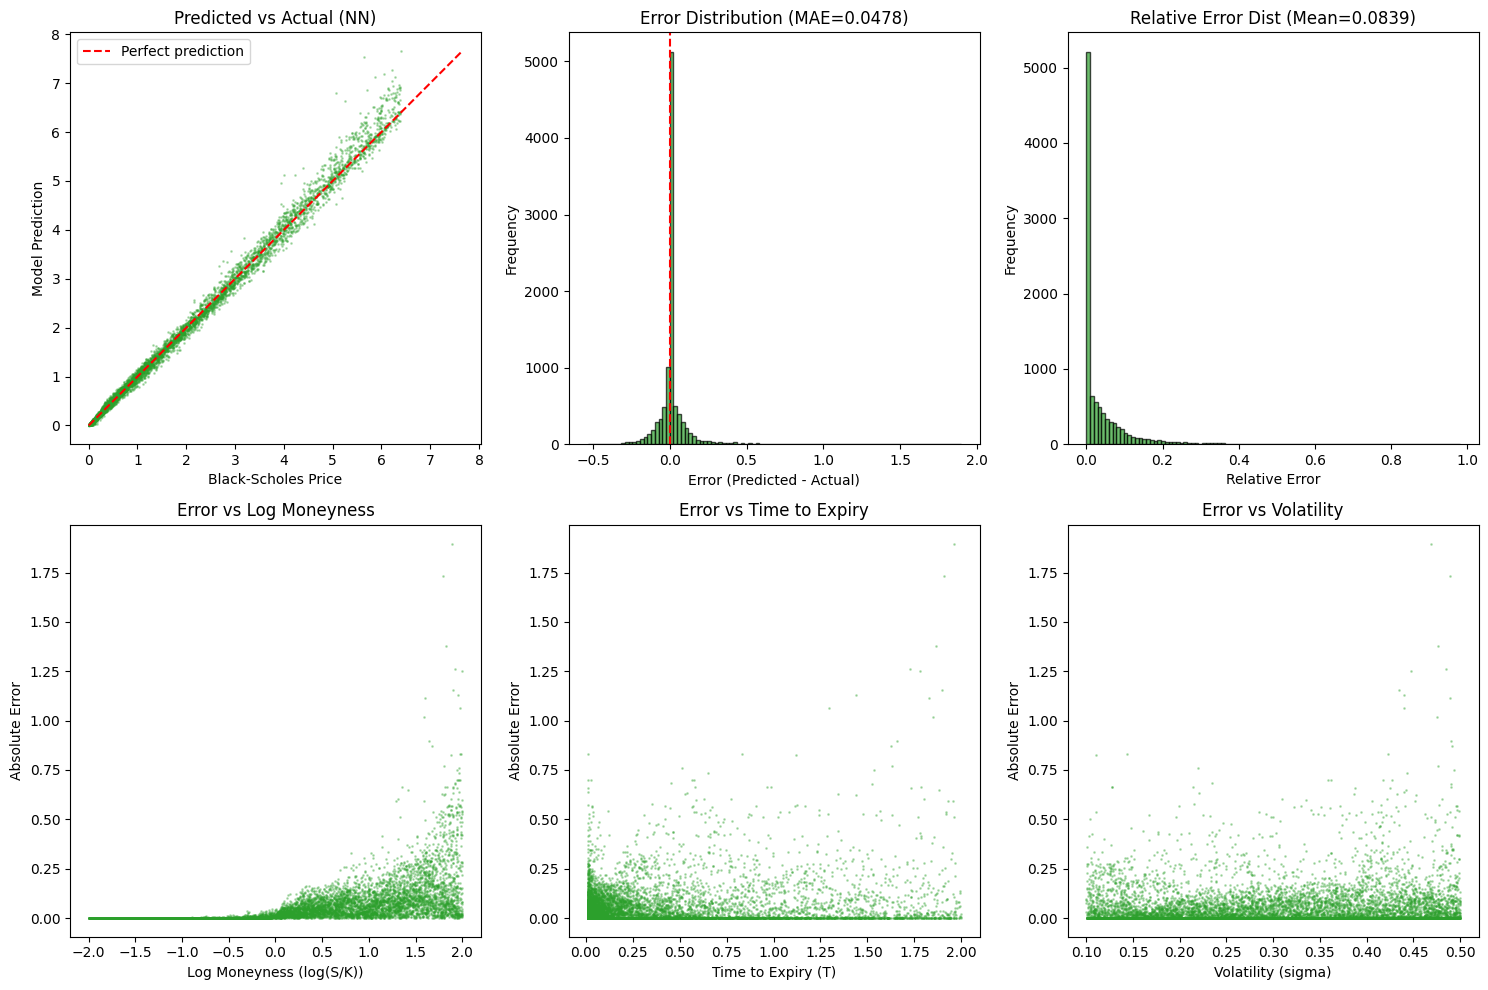

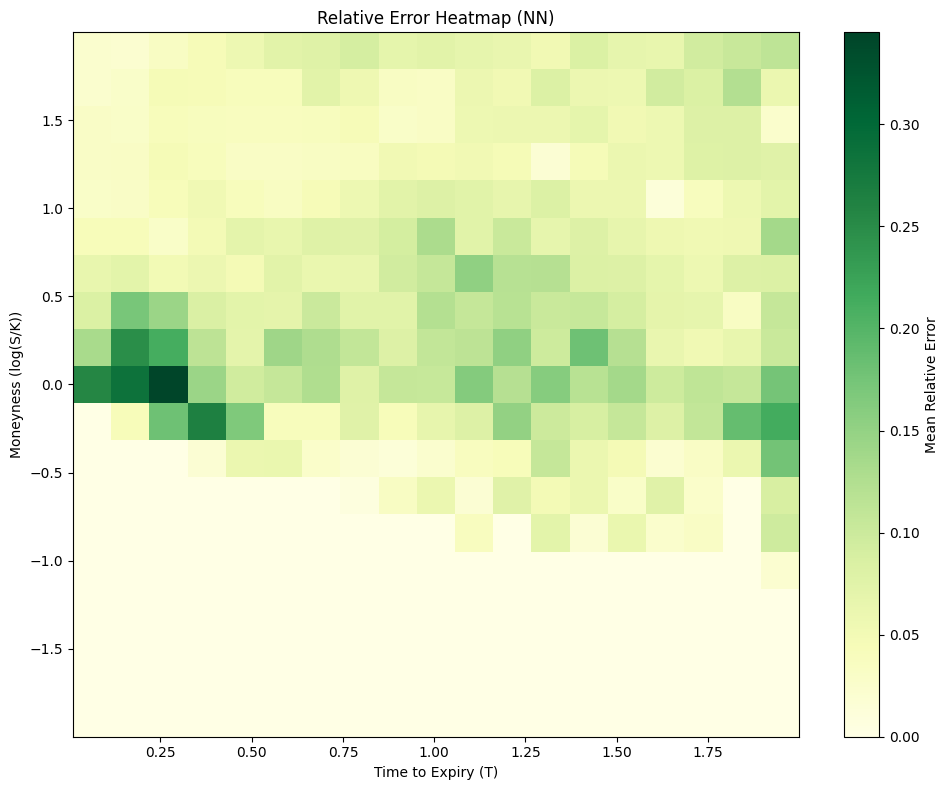

{'mae': np.float32(0.047766905), 'rmse': np.float32(0.10748923), 'mean_relative_error': np.float32(0.08387498), 'median_relative_error': np.float32(0.04823134), 'max_error': np.float32(1.8968425), 'errors': array([ 1.4433980e-02, -5.5324316e-02, -6.5646172e-02, ...,
        7.5293025e-07,  3.5188368e-09, -1.2135457e-09],
      shape=(10000,), dtype=float32), 'abs_errors': array([1.4433980e-02, 5.5324316e-02, 6.5646172e-02, ..., 7.5293025e-07,
       3.5188368e-09, 1.2135457e-09], shape=(10000,), dtype=float32), 'relative_errors': array([0.01567573, 0.0190953 , 0.02475304, ..., 0.        , 0.        ,
       0.        ], shape=(10000,), dtype=float32)}


In [3]:
EVAL_STYLE = {'color': 'tab:green', 'cmap': 'YlGn', 'suffix': '', 'display_name': 'NN'}

X_test_raw, y_test = dataset_bundle.test.X, dataset_bundle.test.y_call
X_test, _ = preprocess_test_data(X_test_raw)
y_pred = predict(nn_model, X_test, norm_params, device="cpu")

def eval():
    metrics = compute_metrics(y_test, 
                          y_pred, 
                          min_value_threshold=0.01)

    plot_validation_results(X_test_raw, 
                        y_test, 
                        y_pred, 
                        metrics, 
                        EVAL_STYLE, 
                        save_dir=None)

    print(metrics)

eval()

As these are benchmark numbers, no further discussion is necessary, although it is worth noting an increase in absolute error over log-moneyness, resulting in a "fan"-shaped error distribution, as shown in the bottom-left plot.

### Log-Moneyness Feature Engineering

Now we train a model on the exact same dataset (refer to the parameters above), except we pass the raw strike price and stock price $S, K$ as inputs, instead of log moneyness. 

**Note: the structure of the model changes to 5 --> 128 --> 128 --> 64 --> 1 due to the increased number of inputs. No other change to model architecture was made.**

In [4]:
from src.models.bs_model import BSModel

cfg = cfg.replace(feature_mode="raw")

RAW_MODEL_ARCHITECTURE = [5, 128, 128, 64, 1]
raw_model = BSModel(layers=RAW_MODEL_ARCHITECTURE)

raw_bundle = generate_bundle(cfg)

X_train, y_train = raw_bundle.train.X, raw_bundle.train.y_call
X_val, y_val = raw_bundle.val.X, raw_bundle.val.y_call

set_seed(42)

raw_model, norm_params = train(
    X_train, y_train, X_val, y_val,
    device=device,
    patience=25,
    epochs=400,
    model=raw_model
)

Epoch 0, Training Loss: 0.99117768, Eval Loss: 0.91774237
Epoch 10, Training Loss: 0.47505376, Eval Loss: 0.43311778
Epoch 20, Training Loss: 0.19367416, Eval Loss: 0.18248603
Epoch 30, Training Loss: 0.12713318, Eval Loss: 0.11777563
Epoch 40, Training Loss: 0.08534667, Eval Loss: 0.08116592
Epoch 50, Training Loss: 0.05929457, Eval Loss: 0.05691343
Epoch 60, Training Loss: 0.04921669, Eval Loss: 0.04788120
Epoch 70, Training Loss: 0.04264764, Eval Loss: 0.04133606
Epoch 80, Training Loss: 0.03633012, Eval Loss: 0.03524892
Epoch 90, Training Loss: 0.03138900, Eval Loss: 0.03043109
Epoch 100, Training Loss: 0.02713421, Eval Loss: 0.02621033
Epoch 110, Training Loss: 0.02344171, Eval Loss: 0.02260108
Epoch 120, Training Loss: 0.02039964, Eval Loss: 0.01957360
Epoch 130, Training Loss: 0.01778015, Eval Loss: 0.01698107
Epoch 140, Training Loss: 0.01550037, Eval Loss: 0.01475977
Epoch 150, Training Loss: 0.01354887, Eval Loss: 0.01287416
Epoch 160, Training Loss: 0.01188388, Eval Loss: 0.

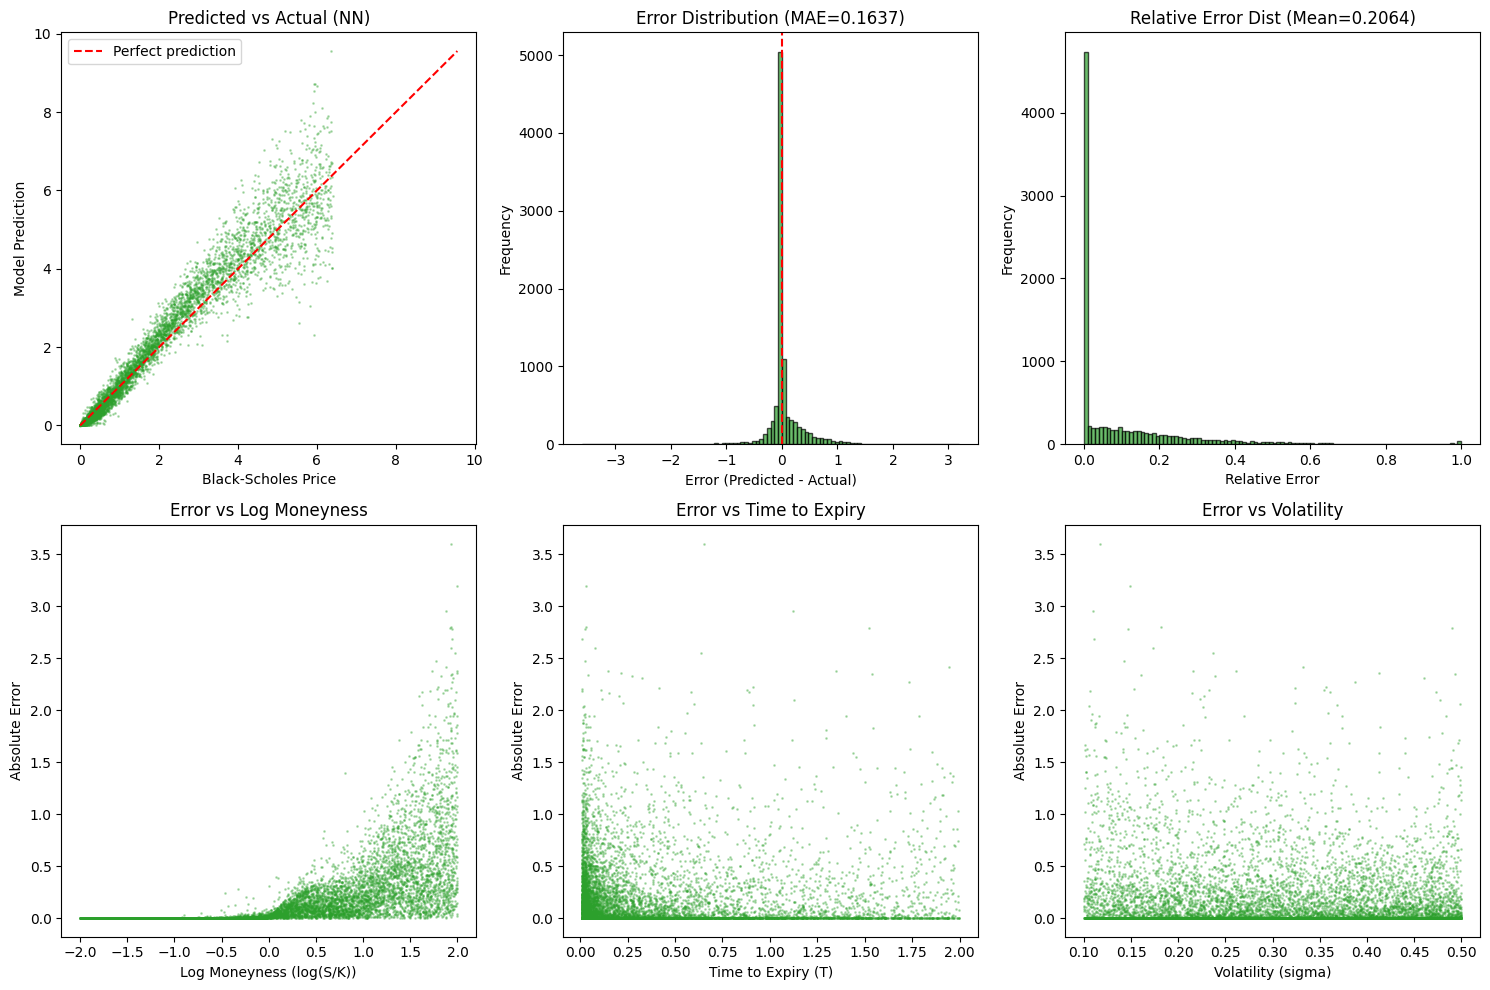

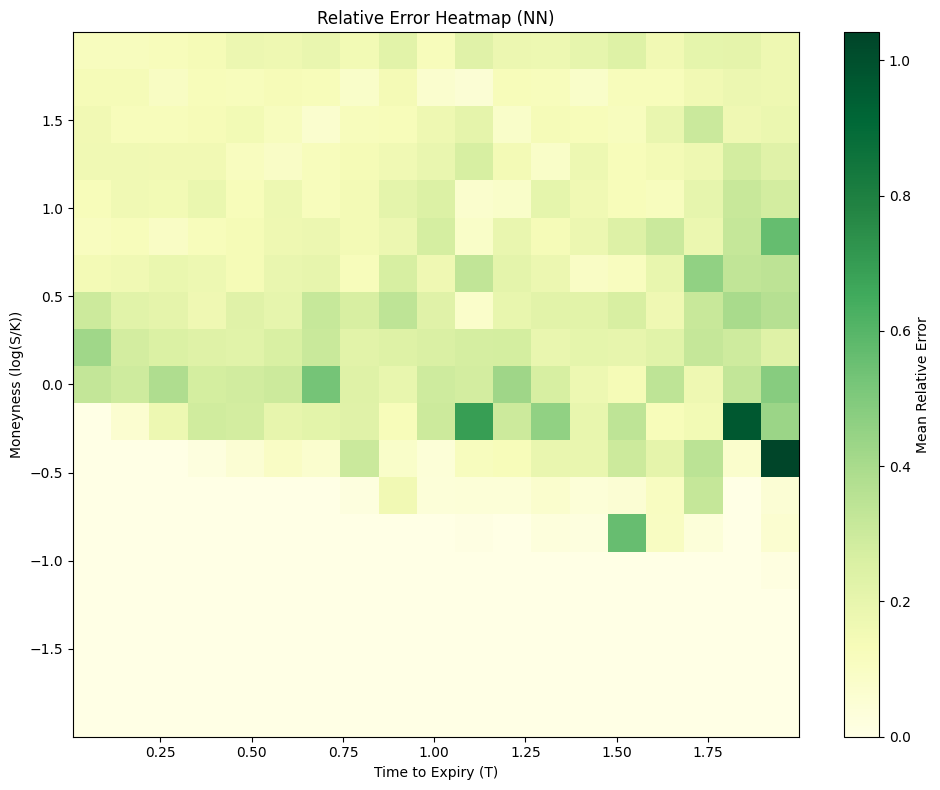

{'mae': np.float32(0.16371071), 'rmse': np.float32(0.35694063), 'mean_relative_error': np.float32(0.2064289), 'median_relative_error': np.float32(0.148828), 'max_error': np.float32(3.601627), 'errors': array([-5.2887022e-02,  1.0136321e+00,  2.7709126e-01, ...,
        3.9585288e-07,  3.2379237e-09,  5.5364424e-10],
      shape=(10000,), dtype=float32), 'abs_errors': array([5.2887022e-02, 1.0136321e+00, 2.7709126e-01, ..., 3.9585288e-07,
       3.2379237e-09, 5.5364424e-10], shape=(10000,), dtype=float32), 'relative_errors': array([0.05743686, 0.34985715, 0.10448212, ..., 0.        , 0.        ,
       0.        ], shape=(10000,), dtype=float32)}


In [5]:
X_test = X_test_raw
y_pred = predict(raw_model, X_test, norm_params, device="cpu")

eval()

pois:
- of course the non feature engineered does way worse
- how is mae and rme an order of magnitude higher... 
- tails explode at high moneyness and low $T$ (high $C$ value as well), but only for abs error??!!!
- shape of error is similar for absolute error, but very different for relative error.
- this is interesting. for relative error it goes the other way!
- probably something to do with the eval again. at high expiry time. it MIGHT just be relative weighing but i dont think increasing $T$ would have that big of an effect on $C$. might also be something systematic. worth investigating.
- magnitude of error increases regardless of what occurs but thats to be expected
- model geometry is now some cursed combination of logs and some monotonically increasing BS (pun intended) on top of the log
- before it was just the monotonically increasing BS which is way easier to model

### Model Architecture

Now we test the impact of model architecture, specifically testing a standard 4 --> 64 --> 64 --> 64 --> 1 (for breadth) and 4 --> 128 --> 128 --> 1 (for depth) against our current 4 --> 128 --> 128 --> 64 --> 1 architecture. Once again, data is consistent with the above tests.

In [7]:
cfg = cfg.replace(feature_mode="log-moneyness")

BREADTH_ARCHITECTURE = [4, 64, 64, 64, 1]
breadth_model = BSModel(layers=BREADTH_ARCHITECTURE)

DEPTH_ARCHITECTURE = [4, 128, 128, 1]
depth_model = BSModel(layers=DEPTH_ARCHITECTURE)

bundle = generate_bundle(cfg)

X_train, y_train = bundle.train.X, bundle.train.y_call
X_val, y_val = bundle.val.X, bundle.val.y_call

breadth_model, norm_params = train(
    X_train, y_train, X_val, y_val,
    device=device,
    patience=25,
    epochs=400,
    model=breadth_model
)

depth_model, _ = train(
    X_train, y_train, X_val, y_val,
    device=device,
    patience=25,
    epochs=400,
    model=depth_model
)

Epoch 0, Training Loss: 0.91250873, Eval Loss: 0.87465692
Epoch 10, Training Loss: 0.57860255, Eval Loss: 0.54037493
Epoch 20, Training Loss: 0.26519638, Eval Loss: 0.24250005
Epoch 30, Training Loss: 0.13547052, Eval Loss: 0.13219517
Epoch 40, Training Loss: 0.08127809, Eval Loss: 0.07608800
Epoch 50, Training Loss: 0.04993555, Eval Loss: 0.04917284
Epoch 60, Training Loss: 0.04116067, Eval Loss: 0.04061995
Epoch 70, Training Loss: 0.03384727, Eval Loss: 0.03324773
Epoch 80, Training Loss: 0.02968007, Eval Loss: 0.02932261
Epoch 90, Training Loss: 0.02669281, Eval Loss: 0.02633290
Epoch 100, Training Loss: 0.02424973, Eval Loss: 0.02395300
Epoch 110, Training Loss: 0.02224262, Eval Loss: 0.02196333
Epoch 120, Training Loss: 0.02039586, Eval Loss: 0.02009743
Epoch 130, Training Loss: 0.01855914, Eval Loss: 0.01824250
Epoch 140, Training Loss: 0.01664430, Eval Loss: 0.01633116
Epoch 150, Training Loss: 0.01470460, Eval Loss: 0.01438743
Epoch 160, Training Loss: 0.01281246, Eval Loss: 0.

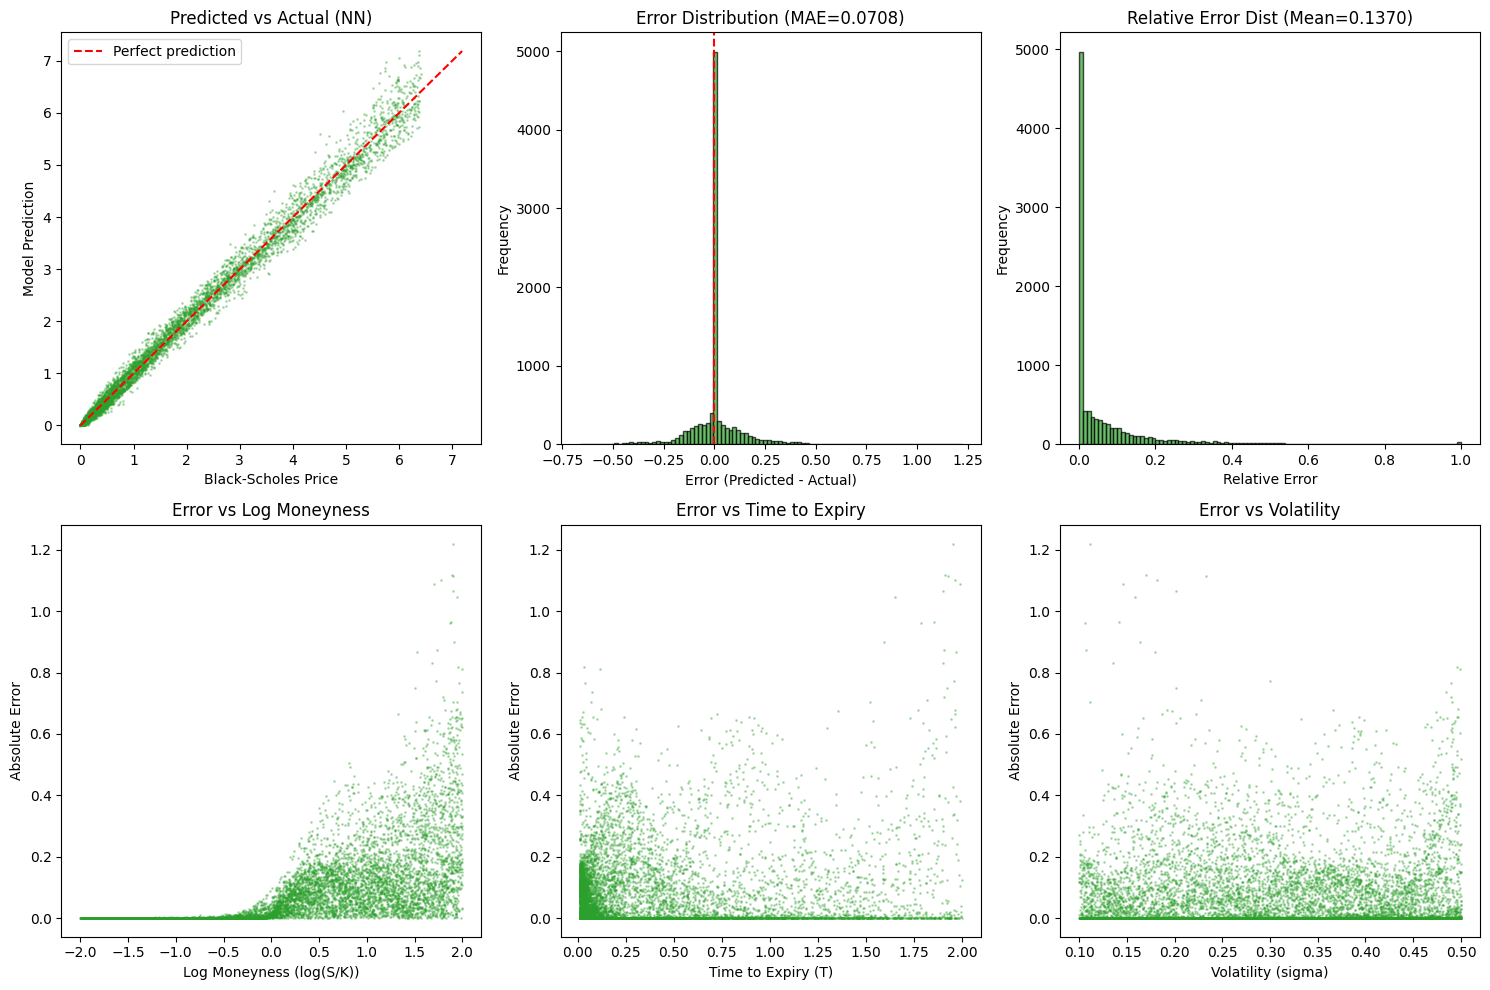

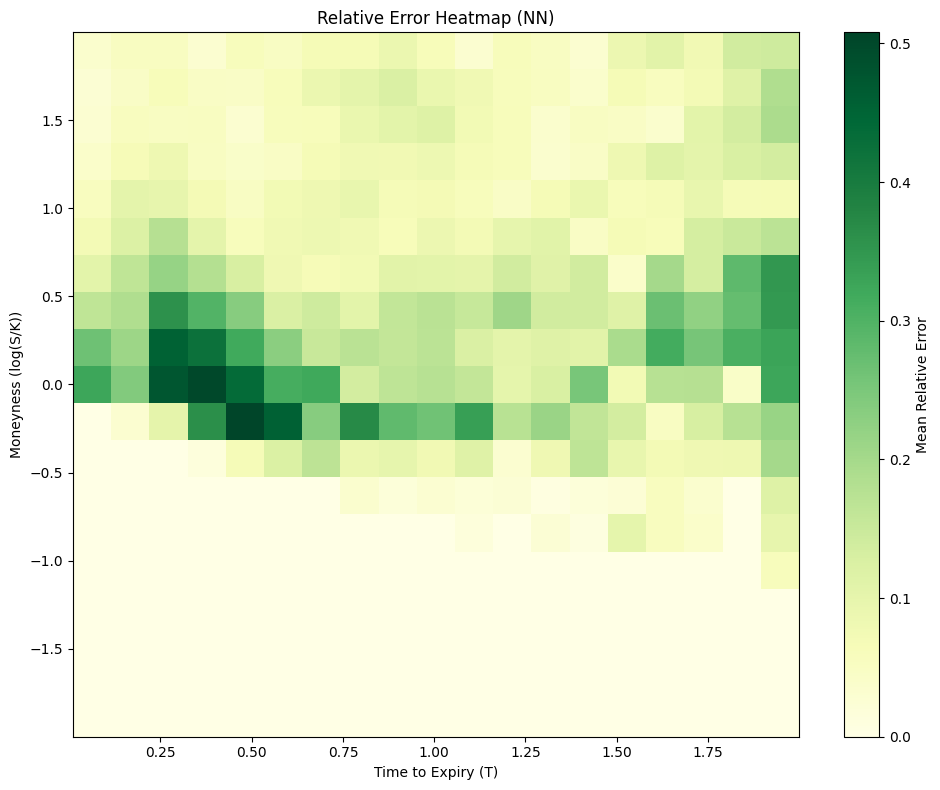

{'mae': np.float32(0.070839345), 'rmse': np.float32(0.13786045), 'mean_relative_error': np.float32(0.13702361), 'median_relative_error': np.float32(0.07843136), 'max_error': np.float32(1.2203121), 'errors': array([-1.4323062e-01, -6.6749573e-02,  9.7090006e-02, ...,
        1.1140479e-06,  1.6778548e-08, -1.5138246e-09],
      shape=(10000,), dtype=float32), 'abs_errors': array([1.4323062e-01, 6.6749573e-02, 9.7090006e-02, ..., 1.1140479e-06,
       1.6778548e-08, 1.5138246e-09], shape=(10000,), dtype=float32), 'relative_errors': array([0.15555267, 0.02303875, 0.03660949, ..., 0.        , 0.        ,
       0.        ], shape=(10000,), dtype=float32)}


In [13]:
X_test, _ = preprocess_test_data(X_test_raw)
y_pred = predict(breadth_model, X_test, norm_params, device="cpu")

eval()

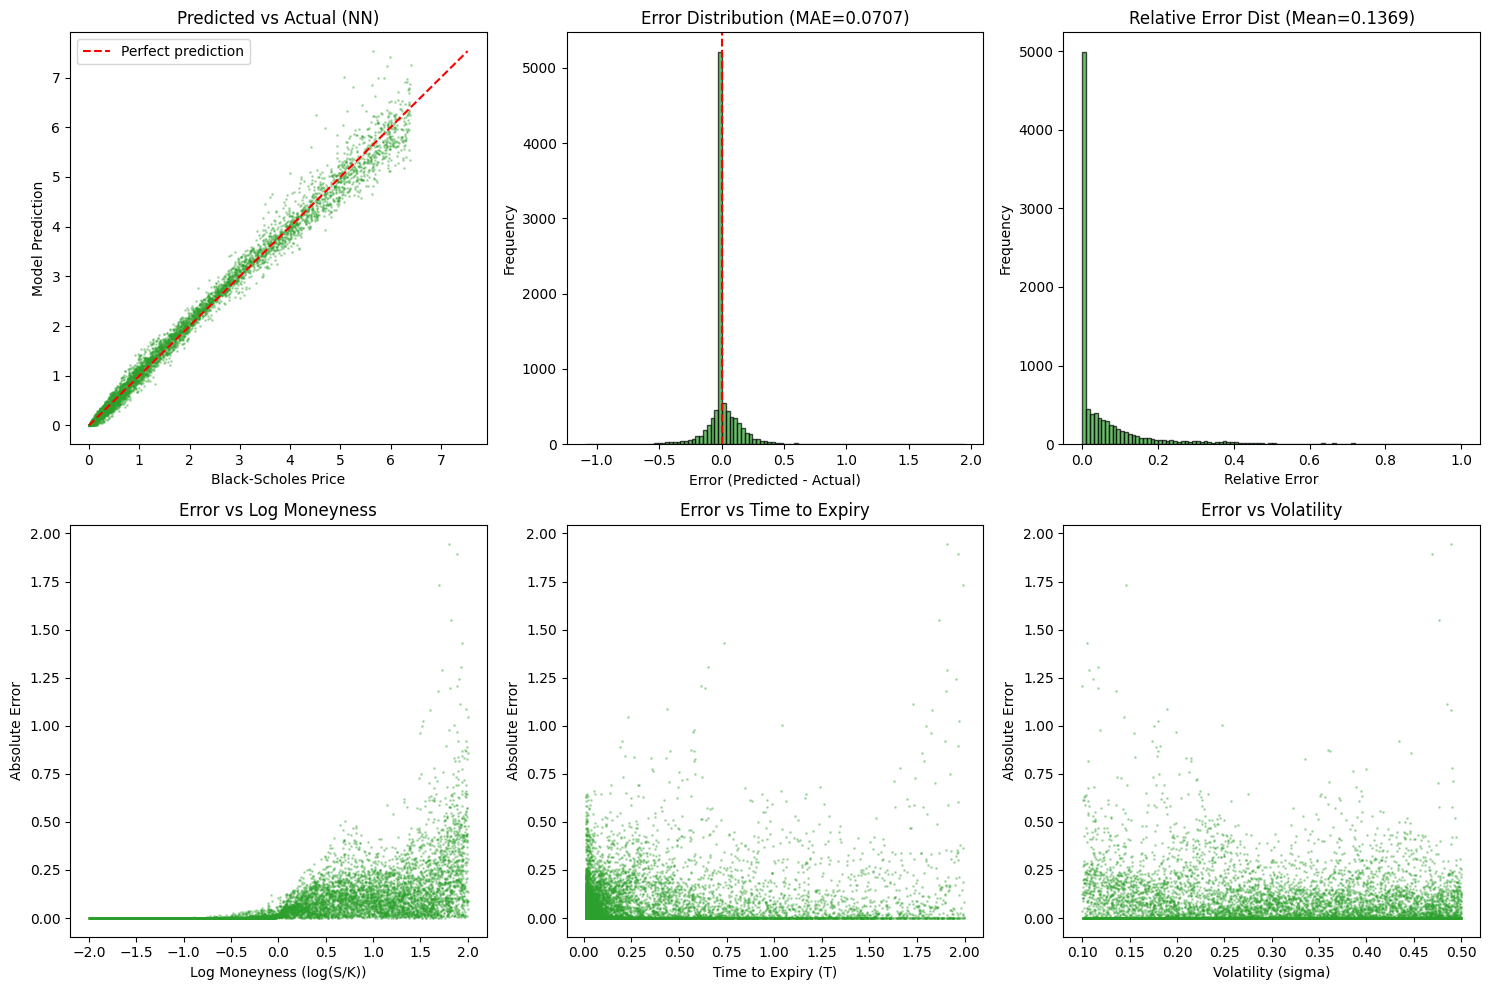

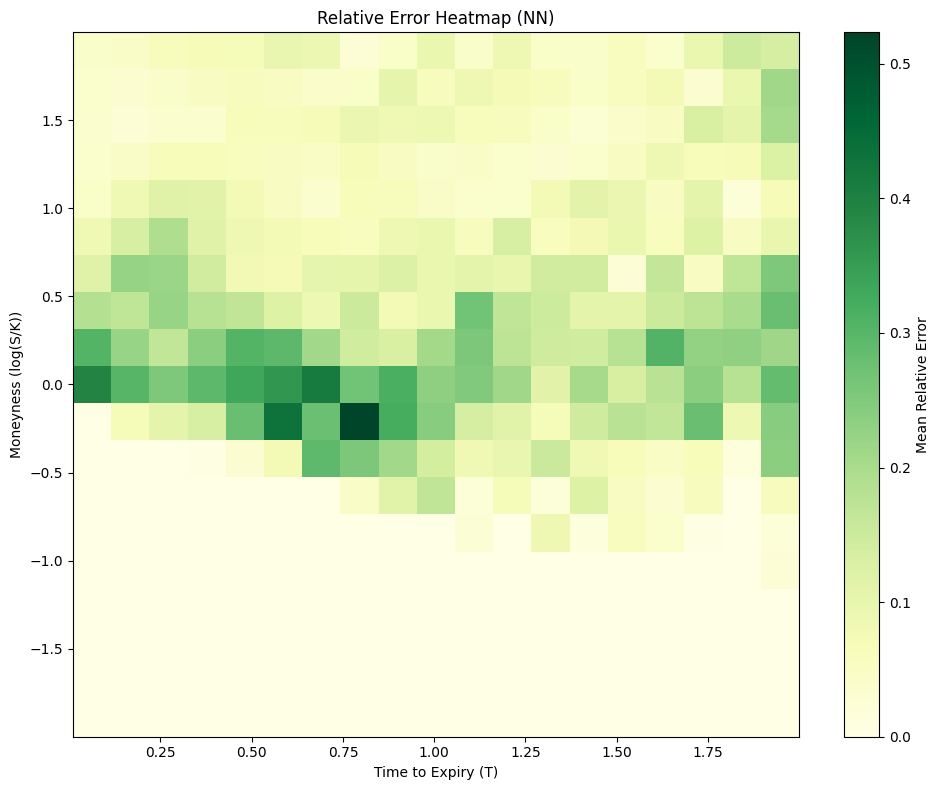

{'mae': np.float32(0.0707106), 'rmse': np.float32(0.14512148), 'mean_relative_error': np.float32(0.13691944), 'median_relative_error': np.float32(0.074803144), 'max_error': np.float32(1.9473777), 'errors': array([ 1.00013554e-01,  9.07907486e-02,  1.78279877e-01, ...,
        2.36449455e-06,  9.32127442e-09, -5.85584914e-10],
      shape=(10000,), dtype=float32), 'abs_errors': array([1.00013554e-01, 9.07907486e-02, 1.78279877e-01, ...,
       2.36449455e-06, 9.32127442e-09, 5.85584914e-10],
      shape=(10000,), dtype=float32), 'relative_errors': array([0.10861766, 0.03133661, 0.06722356, ..., 0.        , 0.        ,
       0.        ], shape=(10000,), dtype=float32)}


In [14]:
X_test, _ = preprocess_test_data(X_test_raw)
y_pred = predict(depth_model, X_test, norm_params, device="cpu")

eval()